# Issue #209 — learned dynamic N/K/ticket policy

This executed notebook is the decision-facing analysis for the method rework.
The experimental unit is one Beijing issue.  The policy learns from pre-event
issue state and explicit N/K/generator parameters.  Seeds are aggregated
within an issue/action and are never policy inputs.  The 2024 outcome namespace
remains sealed.


In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
RESULTS = ROOT / "results/issue-209"
FIGURES = ROOT / "docs/research/figures"
FIGURES.mkdir(parents=True, exist_ok=True)

decision = json.loads((RESULTS / "dynamic_decision.json").read_text())
states = pd.read_csv(RESULTS / "dynamic_issue_states.csv", dtype={"issue": str})
selected = pd.read_csv(RESULTS / "dynamic_selected_actions.csv", dtype={"issue": str})
paths = pd.read_csv(RESULTS / "dynamic_matched_capital_paths.csv", dtype={"issue": str})

print("development issues:", states.issue.nunique())
print("2024 outcomes opened:", decision["seal"]["rows_opened_2024"])
print("selected family:", decision["GATE_A_DYNAMIC_POLICY_FAMILY"])
print("disposition:", decision["GATE_A_DISPOSITION"])


development issues: 620
2024 outcomes opened: 0
selected family: MLP_TWO_PART
disposition: RETAIN_FIXED_CONTROL_NO_PROMOTION


## Frozen design

Fit is through 2021, model-family selection is 2022, and the selected family is
refit through 2022 before choosing 2023 actions.  The active arm cannot choose
NO_BET and tests whether a dynamic mapping exists.  The safe arm can hold cash.
N={3,5,7,8}; K={8,32,128,512}; generator={TOP_VALUE, WR, WOR, NO_BET}.


In [2]:
surface = pd.DataFrame({
    "N anchors": [str(decision["action_surface"]["n"])],
    "K anchors": [str(decision["action_surface"]["k"])],
    "generators": [str(decision["action_surface"]["generators"])],
    "actions": [decision["action_surface"]["action_count"]],
})
display(surface)


,N anchors,K anchors,generators,actions
0,"[3, 5, 7, 8]","[8, 32, 128, 512]","['NO_BET', 'TOP_VALUE', 'WEIGHTED_WOR', 'WEIGH...",49


## 2022 model-family selection

,active_fraction,issues,mean_selected_utility_bps,total_selected_pnl
LOGISTIC_TWO_PART,1.0,62.0,-1.600128,-992.000000
MLP_TWO_PART,1.0,62.0,3.426659,2151.272982


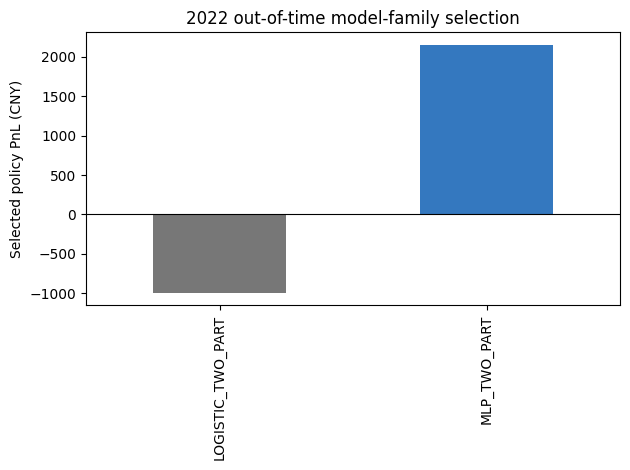

In [3]:
family = pd.DataFrame(decision["model_family_selection_2022"]).T
display(family)
ax = family["total_selected_pnl"].plot.bar(color=["#777777", "#3478bf"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Selected policy PnL (CNY)")
ax.set_title("2022 out-of-time model-family selection")
plt.tight_layout()
plt.savefig(FIGURES / "bj209_dynamic_family_selection.png", dpi=160)
plt.show()


The MLP result remains positive after removing its largest winning
issue, but this is only model-family selection evidence.  It is not a terminal
profitability result.


In [4]:
diag = pd.DataFrame({
    "2022 tune": decision["tune_2022_selection_diagnostics"],
    "2023 calibration": decision["calibration_2023_selection_diagnostics"],
}).T.drop(columns="action_counts")
display(diag)


,ex_largest_total_pnl,issues,largest_issue,largest_issue_pnl,positive_issues,total_pnl
2022 tune,1113.194028,62,22111,1038.078955,12,2151.272982
2023 calibration,-1197.200048,53,23011,35.856648,4,-1161.3434


## 2023 action choices and state conditioning

,issues
action_key,
N7_K8_WEIGHTED_WOR,1
N5_K128_TOP_VALUE,2
N3_K8_WEIGHTED_WOR,5
N5_K8_WEIGHTED_WR,6
N5_K8_WEIGHTED_WOR,7
N7_K8_WEIGHTED_WR,32


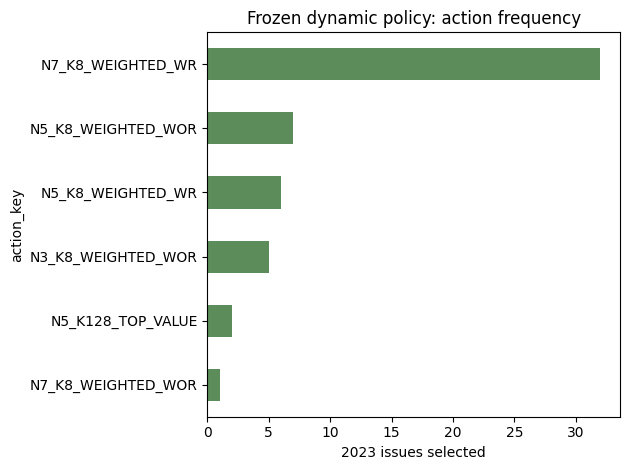

In [5]:
cal = selected[
    (selected.evaluation_role == "CALIBRATION_2023_OUT_OF_TIME")
    & (selected.policy_arm == "LEARNED_ACTIVE_POLICY")
].copy()
counts = cal.action_key.value_counts().sort_values()
display(counts.rename("issues").to_frame())
ax = counts.plot.barh(color="#5b8c5a")
ax.set_xlabel("2023 issues selected")
ax.set_title("Frozen dynamic policy: action frequency")
plt.tight_layout()
plt.savefig(FIGURES / "bj209_dynamic_action_frequency.png", dpi=160)
plt.show()


In [6]:
state_choice = cal.merge(states, on="issue", validate="one_to_one")
display(state_choice.groupby("action_key").agg(
    issues=("issue", "size"),
    mean_matches=("n_matches", "mean"),
    mean_abs_divergence=("divergence_abs_mean", "mean"),
    mean_best_value=("value_best_mean", "mean"),
    realized_pnl=("mean_pnl", "sum"),
))


,issues,mean_matches,mean_abs_divergence,mean_best_value,realized_pnl
action_key,,,,,
N3_K8_WEIGHTED_WOR,5,280.800000,0.044651,1.246329,39.220134
N5_K128_TOP_VALUE,2,178.000000,0.046858,1.270473,-512.000000
N5_K8_WEIGHTED_WOR,7,241.285714,0.047695,1.249792,-64.563534
N5_K8_WEIGHTED_WR,6,194.666667,0.047358,1.247525,-96.000000
N7_K8_WEIGHTED_WOR,1,371.000000,0.051311,1.254681,-16.000000
N7_K8_WEIGHTED_WR,32,298.281250,0.046458,1.254757,-512.000000


## Matched CNY100k capital paths

,ending_capital,capital_return_pct,funded_turnover,max_drawdown_pct,max_consecutive_losses
learned_dynamic,98838.6566,-1.161343,1328.0,1.169381,26
fixed_N7_K8,99152.0,-0.848,848.0,0.848,53
capital_safe,100000.0,0.0,0.0,0.0,0


matched lift vs fixed control: -0.31602327743811554 percentage points


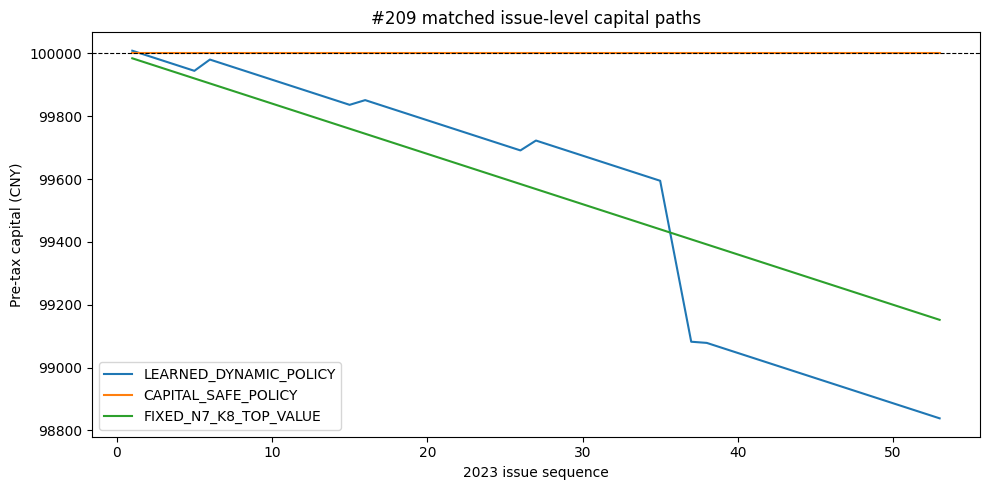

In [7]:
summary = pd.DataFrame({
    "learned_dynamic": decision["dynamic_capital_2023"],
    "fixed_N7_K8": decision["fixed_control_capital_2023"],
    "capital_safe": decision["capital_safe_policy_2023"],
}).T
display(summary[["ending_capital", "capital_return_pct", "funded_turnover", "max_drawdown_pct", "max_consecutive_losses"]])
print("matched lift vs fixed control:", decision["matched_lift_vs_fixed_control"]["matched_lift"], "percentage points")

fig, ax = plt.subplots(figsize=(10, 5))
for arm, frame in paths.groupby("arm", sort=False):
    ax.plot(range(1, len(frame) + 1), frame["equity_after"], label=arm)
ax.axhline(100000, color="black", linestyle="--", linewidth=0.8)
ax.set_xlabel("2023 issue sequence")
ax.set_ylabel("Pre-tax capital (CNY)")
ax.set_title("#209 matched issue-level capital paths")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "bj209_dynamic_matched_capital.png", dpi=160)
plt.show()


## Decision

The learned mapping is genuinely dynamic (six actions), but its 2023 capital is
lower than the matched fixed control.  The safe arm's all-NO_BET choice is a
fallback, not alpha.  Therefore the disposition is
`RETAIN_FIXED_CONTROL_NO_PROMOTION`; 2024 stays sealed.  The next iteration
should enrich the state and regularize action choice toward the accepted
baseline, not merely widen a hindsight parameter grid.
